# K-Means Clustering Demo

**Problem:** group 300 unlabelled points into clusters with **k-means**, choose the number of clusters with the **elbow method**, and see a case where k-means fails but **DBSCAN** works. The code follows the *K-mean Implementation in Python*, *Elbow Method* and *DBSCAN* slides of the lecture, updated for the current scikit-learn.

**How to run:** this notebook runs in your browser on the course website. Use **Run → Run All Cells**, or press **Shift+Enter** to run one cell at a time. The first run loads scikit-learn and Matplotlib, which takes a few seconds.

**Expected result:** four clusters of 75 points each with their centres marked, an elbow plot that bends clearly at k = 4, and a "two moons" example where k-means cuts both moons in half while DBSCAN separates them correctly.

## 1. Imports
NumPy holds the data, Matplotlib draws the plots, and scikit-learn provides the example datasets, the two clustering algorithms and a score that compares a clustering with the true groups.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score
import warnings

# in the browser, a helper library of scikit-learn prints a harmless deprecation warning; hide it
warnings.filterwarnings("ignore", message="JsProxy.as_object_map", category=RuntimeWarning)

## 2. Unlabelled data
`make_blobs` creates points around four centres. It also returns the true group of each point (`y_true`); k-means never sees it, we only keep it to check the result.

> The slide imports `make_blobs` from `sklearn.datasets.samples_generator`. That module was removed in scikit-learn 0.24; today it is imported from `sklearn.datasets`.

Data shape: (300, 2)


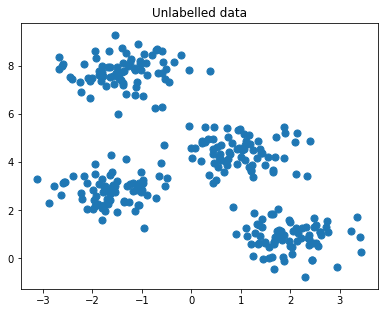

In [2]:
# 300 points around 4 centres; random_state fixes the data so every run gives the same points
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
print("Data shape:", X.shape)  # 300 rows (points), 2 columns (features)

plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Unlabelled data")
plt.show()

## 3. K-means with k = 4
K-means places k centres, assigns every point to its nearest centre, moves each centre to the mean of its points, and repeats until the centres stop moving. The result depends on the starting centres, so `n_init=10` runs the algorithm 10 times from different starts and keeps the run with the lowest **inertia** (the total squared distance of the points to their centres).

Points per cluster: [75 75 75 75]
Cluster centres:
[[ 0.95  4.42]
 [ 1.98  0.87]
 [-1.37  7.75]
 [-1.58  2.83]]
Agreement with the true groups (1 = perfect): 1.0


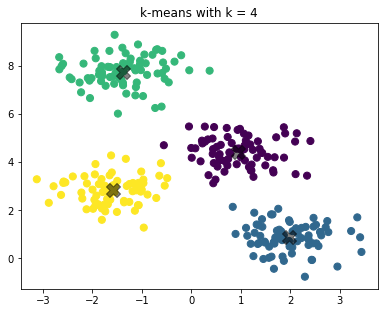

In [3]:
# fit k-means with 4 clusters; random_state fixes the starting centres
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)  # cluster number (0-3) of each point

print("Points per cluster:", np.bincount(y_kmeans))
print("Cluster centres:")
print(np.round(kmeans.cluster_centers_, 2))
print("Agreement with the true groups (1 = perfect):", round(adjusted_rand_score(y_true, y_kmeans), 2))

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap="viridis")
centres = kmeans.cluster_centers_
plt.scatter(centres[:, 0], centres[:, 1], c="black", s=200, alpha=0.5, marker="X")  # the 4 centres
plt.title("k-means with k = 4")
plt.show()

## 4. Choosing k with the elbow method
In practice we don't know k. We fit k-means for k = 1 to 10 and plot the inertia (the slide calls it *distortion*). Inertia always falls as k grows, so we look for the **elbow**: the k after which adding another cluster no longer reduces it much.

k =  1: inertia =  2812.1
k =  2: inertia =  1190.8
k =  3: inertia =   546.9
k =  4: inertia =   212.0
k =  5: inertia =   188.8
k =  6: inertia =   170.7
k =  7: inertia =   154.9
k =  8: inertia =   137.5
k =  9: inertia =   123.8
k = 10: inertia =   112.4


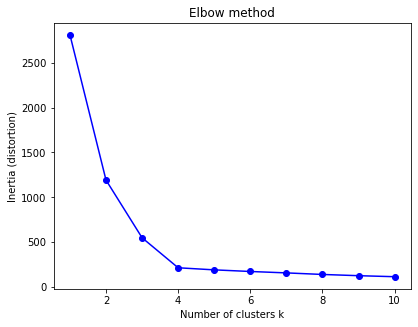

In [4]:
# fit k-means for k = 1..10 and record the inertia of each fit
ks = range(1, 11)
inertias = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertias.append(model.inertia_)

for k, inertia in zip(ks, inertias):
    print(f"k = {k:2d}: inertia = {inertia:7.1f}")

plt.plot(ks, inertias, "bo-")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia (distortion)")
plt.title("Elbow method")
plt.show()

### What do you notice?
Where is the elbow, and why does the curve flatten after it?

<details>
<summary>Answer</summary>

The elbow is at **k = 4**. The inertia falls steeply up to 4 clusters (2812 → 1191 → 547 → 212) and only slowly after that (212 → 189 → 171 → …). The data has four real groups: up to k = 4, each new centre captures a group of its own. After that, extra centres only split groups that are already well described, so the gain is small. This matches the agreement score of 1.0 in section 3.
</details>

## 5. When k-means fails: clusters that are not round
K-means assigns each point to the nearest centre, so it can only draw straight borders between clusters. The "two moons" dataset has two curved groups. DBSCAN instead grows clusters from dense regions: a point belongs to a cluster if enough neighbours (`min_samples`) lie within the distance `eps`. Points in sparse regions get the label -1 (noise). We use the parameters from the DBSCAN slide.

k-means agreement with the true moons: 0.24
DBSCAN agreement with the true moons:  1.0
DBSCAN clusters found: 2 | noise points: 0


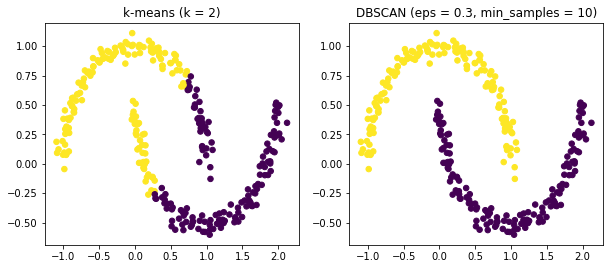

In [5]:
# two interleaving half circles; the true groups are curved, not round
X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=0)

km_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_moons)
db_labels = DBSCAN(eps=0.3, min_samples=10).fit_predict(X_moons)  # no k needed; -1 = noise

print("k-means agreement with the true moons:", round(adjusted_rand_score(y_moons, km_labels), 2))
print("DBSCAN agreement with the true moons: ", round(adjusted_rand_score(y_moons, db_labels), 2))
print("DBSCAN clusters found:", len(set(db_labels) - {-1}), "| noise points:", int((db_labels == -1).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=km_labels, s=30, cmap="viridis")
axes[0].set_title("k-means (k = 2)")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=db_labels, s=30, cmap="viridis")
axes[1].set_title("DBSCAN (eps = 0.3, min_samples = 10)")
plt.show()

### Try it
In section 2, change `cluster_std=0.60` to `cluster_std=1.5`, then run all cells again. What happens to the clusters and to the elbow?

<details>
<summary>Answer</summary>

With `cluster_std=1.5` the four groups spread out and overlap. K-means still finds four clusters of similar size (74, 73, 72 and 81 points), but many points in the overlap land in a different cluster from their true group, and the agreement score drops from 1.0 to 0.59. The elbow is much less clear because the inertia now falls more evenly (3936 → 2014 → 1398 → 1008 → 876 → 752 → …). The plot alone no longer shows that there are four groups. This is where field knowledge or a business decision (*How to Choose the Right K Number* slide) is needed.
</details>